# Aleatorización y recocido simulado

**Serie:** Metaheurísticas desde cero · Métodos de trayectoria · Notebook 05

Navegación: [← 04 VNS y LNS](04-vns-lns.ipynb) · [06 Búsqueda tabú →](../02-metodos-con-memoria/06-busqueda-tabu.ipynb)

## Contenido
1. Qué vas a aprender y prerrequisitos
2. Utilidades (TSP y 2-opt con delta)
3. Dónde entra el azar: reinicio, construcción aleatorizada y perturbación
4. Estrategia evolutiva (1+1)
5. Búsqueda local que acepta no mejoras
6. Recocido simulado: derivación de la probabilidad de Metropolis (y verificación numérica)
7. Implementación de SA para TSP
8. Esquemas de enfriamiento: geométrico, lineal, logarítmico (Hajek)
9. Temperatura inicial por tasa de aceptación objetivo
10. Longitud de cadena y recalentamiento
11. Visualización de la trayectoria de aceptación
12. SA en una función continua multimodal
13. Comparación final sobre TSP, ventajas/limitaciones, resumen, ejercicios, referencias

## 1. Qué vas a aprender y prerrequisitos

**Qué vas a aprender**
- Las tres formas básicas de introducir aleatoriedad en una búsqueda: *reiniciar*, *construir de forma aleatorizada* y *perturbar*.
- Qué ocurre cuando una búsqueda acepta movimientos que **no** mejoran, desde la regla más tosca (probabilidad fija) hasta la regla de Metropolis.
- **Derivar** la probabilidad de aceptación $\min(1,e^{-\Delta/T})$ a partir de la distribución de Boltzmann y del balance detallado, y **comprobarla numéricamente** en un TSP diminuto cuyo espacio de búsqueda se enumera completo.
- Diseñar un SA: esquema de enfriamiento, temperatura inicial por tasa de aceptación objetivo, longitud de cadena y recalentamiento.
- Visualizar cómo la tasa de aceptación cae al enfriarse y cómo el recocido cruza barreras en una función continua con muchos mínimos locales.

**Prerrequisitos:** búsqueda local y 2-opt ([03](03-busqueda-local-ils.ipynb)); el vecindario 2-opt y sus deltas se repasan en [04](04-vns-lns.ipynb). Probabilidad básica (esperanza, distribuciones discretas).

## 2. Utilidades

Instancias euclídeas aleatorias; un tour es una lista que es permutación de $0..n-1$. El movimiento básico es **2-opt**: invertir el tramo $t[i..j]$,
con delta en $O(1)$:

$$\Delta = d(a,c) + d(b,e) - d(a,b) - d(c,e),\quad a=t[i-1],\ b=t[i],\ c=t[j],\ e=t[j+1].$$

Para tener comparaciones justas **contaremos evaluaciones de vecinos** (cada delta calculado es una evaluación) en vez de segundos.
Para los bucles escalares usamos `random.Random`, que es mucho más rápido que `numpy.random.Generator` para números sueltos.

In [1]:
import time, math, random, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import brentq

SEED = 2024
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

class TSP:
    '''Instancia euclídea aleatoria de n ciudades en [0,100]^2.'''
    def __init__(self, n, seed):
        rng = np.random.default_rng(seed)
        self.n = n
        self.xy = rng.random((n, 2)) * 100
        self.D = np.linalg.norm(self.xy[:, None, :] - self.xy[None, :, :], axis=2)
        self.d = self.D.tolist()
    def largo(self, t):
        t = np.asarray(t)
        return float(self.D[t, np.roll(t, -1)].sum())

def es_tour(P, t):
    return len(t) == P.n and sorted(t) == list(range(P.n))

def delta_2opt(P, t, i, j):
    d, n = P.d, P.n
    a, b, c, e = t[i - 1], t[i], t[j], t[(j + 1) % n]
    return d[a][c] + d[b][e] - d[a][b] - d[c][e]

def aplicar_2opt(t, i, j):
    return t[:i] + t[i:j + 1][::-1] + t[j + 1:]

def graficar_tour(P, t, ax=None, titulo=""):
    ax = ax or plt.gca()
    tt = list(t) + [t[0]]
    ax.plot(P.xy[tt, 0], P.xy[tt, 1], "-o", ms=3.5, lw=1.1)
    ax.set_title(f"{titulo}\nlargo = {P.largo(t):.1f}", fontsize=10)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])

def vecino_mas_cercano(P, inicio=0, rnd=None, k=1):
    '''Vecino más cercano. Con k>1 y rnd, elige al azar entre los k más cercanos (construcción aleatorizada).'''
    t, libres = [inicio], set(range(P.n)) - {inicio}
    while libres:
        ult = t[-1]
        orden = sorted(libres, key=lambda c: P.d[ult][c])
        prox = orden[0] if (rnd is None or k == 1) else orden[rnd.randrange(min(k, len(orden)))]
        t.append(prox); libres.remove(prox)
    return t

def local_2opt(P, t, cont):
    '''2-opt de primera mejora. cont es una lista [evaluaciones]; se incrementa por cada delta calculado.'''
    t = list(t); n = P.n; mejoro = True
    while mejoro:
        mejoro = False
        for i in range(1, n - 1):
            for j in range(i + 1, n):
                if i == 1 and j == n - 1:
                    continue
                cont[0] += 1
                if delta_2opt(P, t, i, j) < -1e-9:
                    t = aplicar_2opt(t, i, j); mejoro = True
                    break
            if mejoro: break
    return t, P.largo(t)

# Verificación del delta y de la validez
P0 = TSP(50, seed=3)
rnd = random.Random(0)
t = np.random.default_rng(0).permutation(P0.n).tolist()
for _ in range(500):
    i, j = sorted(rnd.sample(range(1, P0.n), 2))
    t2 = aplicar_2opt(t, i, j)
    assert es_tour(P0, t2) and abs((P0.largo(t2) - P0.largo(t)) - delta_2opt(P0, t, i, j)) < 1e-9
print("500 movimientos 2-opt aleatorios: delta == recomputación y tours válidos.")

500 movimientos 2-opt aleatorios: delta == recomputación y tours válidos.


## 3. Dónde entra el azar

Una búsqueda local determinista termina en el primer óptimo local que encuentra. El azar sirve para **diversificar**. Tres lugares donde aparece:

| Componente | Idea | Ejemplo en TSP |
|---|---|---|
| **Reinicio aleatorio** | Empezar de nuevo desde otra solución al azar | permutación aleatoria + 2-opt |
| **Construcción aleatorizada** | El constructivo elige al azar entre las mejores opciones (lista restringida de candidatos) | vecino más cercano eligiendo entre los $k$ más cercanos |
| **Perturbación** | Modificar la solución actual lo justo para salir del óptimo local (ILS) | *doble puente* |

El **doble puente** (Martin, Otto y Felten) parte el tour en cinco tramos y reordena los tres interiores: $X\,B\,C\,D \to X\,D\,C\,B$ (con $X$ = cola + cabeza, ya que el tour es cíclico).
Cambia **4 aristas** y no puede construirse como una secuencia de movimientos 2-opt o or-opt "razonables", de modo que una búsqueda local con esos vecindarios difícilmente lo deshace.
Lo comprobamos contando aristas distintas entre el tour original y el perturbado:

In [2]:
def aristas(t):
    n = len(t)
    return {frozenset((t[k], t[(k + 1) % n])) for k in range(n)}

def doble_puente(t, rnd):
    '''X B C D -> X D C B: tramos A=t[:p1] (con la cola), B, C, D (sin invertir cada uno).'''
    n = len(t)
    p1, p2, p3, p4 = sorted(rnd.sample(range(1, n), 4))
    A_, B, C, D, E = t[:p1], t[p1:p2], t[p2:p3], t[p3:p4], t[p4:]
    return A_ + D + C + B + E

def segmento_swap(t, rnd):
    '''A C B D (intercambio de dos tramos adyacentes): solo 3 aristas cambian.'''
    n = len(t)
    p1, p2, p3 = sorted(rnd.sample(range(1, n), 3))
    return t[:p1] + t[p2:p3] + t[p1:p2] + t[p3:]

rnd = random.Random(1)
t = list(range(P0.n))
from collections import Counter
cambios_db, cambios_ss = Counter(), Counter()
for _ in range(2000):
    nuevo = doble_puente(t, rnd); assert es_tour(P0, nuevo)
    cambios_db[len(aristas(t) - aristas(nuevo))] += 1
    nuevo = segmento_swap(t, rnd); assert es_tour(P0, nuevo)
    cambios_ss[len(aristas(t) - aristas(nuevo))] += 1
print("Aristas eliminadas por el doble puente           (nº aristas: frecuencia):", dict(sorted(cambios_db.items())))
print("Aristas eliminadas por el intercambio de tramos  (nº aristas: frecuencia):", dict(sorted(cambios_ss.items())))

Aristas eliminadas por el doble puente           (nº aristas: frecuencia): {3: 19, 4: 1981}
Aristas eliminadas por el intercambio de tramos  (nº aristas: frecuencia): {2: 6, 3: 1994}


El doble puente cambia 4 aristas (en el pequeño porcentaje de casos con tramos de longitud 1 adyacentes, una arista nueva coincide con una vieja y el conteo baja a 3), mientras que el intercambio de dos tramos adyacentes
"A C B D", escrito sobre un tour cíclico, cambia solo 3 (es la inserción de segmento de 3-opt, la que vimos en la notebook 04). Usaremos el de 4 aristas como perturbación.

### Experimento: reinicio vs construcción aleatorizada vs perturbación (mismo presupuesto)
Damos a cada estrategia el mismo presupuesto de **evaluaciones de vecinos** ($E=1\,500\,000$) y repetimos con 10 semillas sobre una instancia con $n=100$ ciudades.
- *Reinicio*: permutación aleatoria $\to$ 2-opt, guardar el mejor.
- *Construcción aleatorizada*: vecino más cercano eligiendo entre los 3 más cercanos $\to$ 2-opt.
- *Perturbación (ILS)*: 2-opt desde vecino más cercano; luego doble puente $\to$ 2-opt, aceptar si mejora.

In [3]:
def reinicio_aleatorio(P, rnd, E):
    cont = [0]; mejor = float("inf")
    while cont[0] < E:
        t = list(range(P.n)); rnd.shuffle(t)
        _, L = local_2opt(P, t, cont); mejor = min(mejor, L)
    return mejor

def construccion_aleatorizada(P, rnd, E, k=3):
    cont = [0]; mejor = float("inf")
    while cont[0] < E:
        t = vecino_mas_cercano(P, rnd.randrange(P.n), rnd, k)
        _, L = local_2opt(P, t, cont); mejor = min(mejor, L)
    return mejor

def ils_db(P, rnd, E):
    cont = [0]
    t, L = local_2opt(P, vecino_mas_cercano(P, rnd.randrange(P.n)), cont)
    while cont[0] < E:
        t2, L2 = local_2opt(P, doble_puente(t, rnd), cont)
        if L2 < L - 1e-9: t, L = t2, L2
    return L

E_BUDGET = 1_500_000
P100 = TSP(100, seed=31)
estrategias = {"Reinicio aleatorio": reinicio_aleatorio, "Construcción aleatorizada (k=3)": construccion_aleatorizada, "Perturbación (ILS, doble puente)": ils_db}
res3 = {}
t0 = time.perf_counter()
for nombre, f in estrategias.items():
    res3[nombre] = [f(P100, random.Random(s), E_BUDGET) for s in range(10)]
print(f"({time.perf_counter() - t0:.0f} s)")
tabla = pd.DataFrame({k: {"media": np.mean(v), "desv. est.": np.std(v, ddof=1), "mejor": np.min(v), "peor": np.max(v)} for k, v in res3.items()}).T
print(tabla.round(2).to_string())

(7 s)
                                   media  desv. est.   mejor    peor
Reinicio aleatorio                831.46        7.42  816.64  844.31
Construcción aleatorizada (k=3)   827.76        8.69  815.10  843.72
Perturbación (ILS, doble puente)  811.50        6.79  802.02  824.35


Lectura de la tabla: la **perturbación guiada por el óptimo actual (ILS)** es claramente la mejor de las tres con el mismo presupuesto de evaluaciones, con una diferencia muy superior a la desviación estándar.
La causa es que la búsqueda local de una solución perturbada es *corta* (casi todo el tour ya está bien) y no se desperdician evaluaciones reconstruyendo estructura.
La construcción aleatorizada y el reinicio total quedan muy cerca entre sí (la diferencia entre ellos es del orden de la desviación estándar): cada uno "olvida" lo aprendido en la búsqueda anterior,
así que solo se beneficia de tomar el mejor de muchos óptimos locales independientes, con rendimientos decrecientes.

## 4. Estrategia evolutiva (1+1)

La **(1+1)-ES** mantiene un solo individuo (el "padre") y en cada generación crea un solo hijo por **mutación**; el mejor de los dos sobrevive
(notación $(\mu+\lambda)$: $\mu=1$ padres, $\lambda=1$ hijos, selección entre padres e hijos). Aceptamos el hijo si $f(y)\le f(x)$ (aceptar empates ayuda a recorrer mesetas).

```
(1+1)-ES(x):
    repetir:
        y = mutar(x)
        si f(y) <= f(x): x = y
```

Para TSP tomamos como mutación $k=1+\text{Poisson}(\lambda)$ inversiones 2-opt aleatorias consecutivas. Con $\lambda=0$ (solo una inversión) la ES no puede salir de un óptimo 2-opt (solo se mueve por mesetas);
con $\lambda>0$ puede componer varios movimientos y así atravesar barreras de dos o tres pasos. Es el algoritmo más simple que mezcla *explorar* (mutación) y *seleccionar* (aceptación elitista).

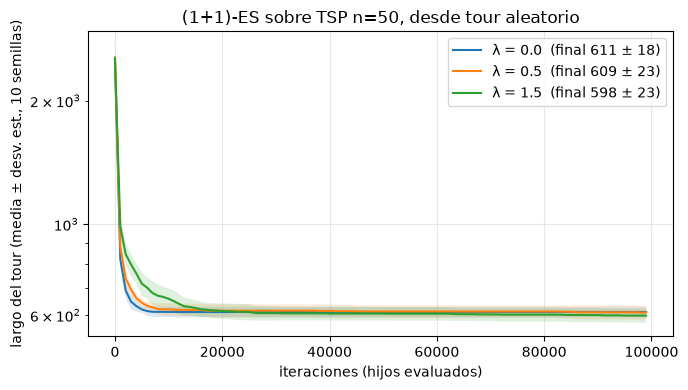

In [4]:
def poisson_knuth(lam, rnd):
    L, k, p = math.exp(-lam), 0, 1.0
    while True:
        p *= rnd.random()
        if p <= L: return k
        k += 1

def es_1mas1(P, rnd, n_iter, lam=0.5, t_ini=None, traza_cada=0):
    n, d = P.n, P.d
    t = t_ini[:] if t_ini is not None else rnd.sample(range(n), n)
    L = P.largo(t); traza = []
    for it in range(n_iter):
        y, dl = t, 0.0
        for _ in range(1 + poisson_knuth(lam, rnd)):
            i, j = sorted(rnd.sample(range(1, n), 2))
            dl += delta_2opt(P, y, i, j); y = aplicar_2opt(y, i, j)
        if dl <= 1e-12:
            t, L = y, L + dl
        if traza_cada and it % traza_cada == 0: traza.append(L)
    return t, L, traza

fig, ax = plt.subplots(figsize=(7, 4))
for lam in [0.0, 0.5, 1.5]:
    curvas = []
    for s in range(10):
        t, L, tr = es_1mas1(P0, random.Random(s), 100_000, lam, traza_cada=1000)
        assert es_tour(P0, t) and abs(P0.largo(t) - L) < 1e-6          # largo incremental == recalculado
        curvas.append(tr)
    C = np.array(curvas); mu, sd = C.mean(0), C.std(0, ddof=1)
    x = np.arange(C.shape[1]) * 1000
    ax.plot(x, mu, label=f"λ = {lam}  (final {mu[-1]:.0f} ± {sd[-1]:.0f})"); ax.fill_between(x, mu - sd, mu + sd, alpha=0.15)
ax.set_xlabel("iteraciones (hijos evaluados)"); ax.set_ylabel("largo del tour (media ± desv. est., 10 semillas)")
ax.set_title("(1+1)-ES sobre TSP n=50, desde tour aleatorio"); ax.set_yscale("log"); ax.legend()
plt.tight_layout(); plt.show()

En la figura, las tres curvas caen muy rápido y luego se aplanan: la ES converge pronto a un óptimo local de calidad parecida a la de 2-opt. La leyenda da el largo final medio ± desv. est. para cada $\lambda$;
con 10 semillas las diferencias entre valores de $\lambda$ son del orden de la desviación estándar, así que solo se puede afirmar de forma tentativa que mutaciones algo mayores ayudan a seguir bajando después de la meseta inicial.
Una ES elitista no puede subir de nivel de energía: necesitamos aceptar empeoramientos.

## 5. Búsqueda local que acepta no mejoras

La (1+1)-ES es *elitista*: nunca acepta empeorar. La siguiente generalización permite empeorar. Primero, la regla más tosca: aceptar un vecino aleatorio
**peor** con una probabilidad fija $\alpha$, independiente de cuánto empeora. Hay que separar dos soluciones:
la **actual** $x$ (la que se mueve) y la **mejor encontrada** $x^\ast$ (la que se devuelve).

```
BusquedaNoMejora(x, alpha):
    x* = x
    repetir:
        y = vecino aleatorio de x
        si f(y) < f(x)  o  random() < alpha:   x = y
        si f(x) < f(x*): x* = x
```

El problema de una $\alpha$ fija: ignora **cuánto** empeora el movimiento. Un salto que empeora 1 % y uno que empeora 100 % se aceptan con la misma probabilidad.
Con $\alpha$ pequeño la búsqueda se parece a un descenso; con $\alpha$ grande, a un paseo aleatorio.

 alpha  mejor largo (media)  desv. est.  largo actual final (media)
     0               604.01        0.00                      604.01
0.0001               589.79       12.00                      613.09
 0.001               588.07        3.32                      718.51
  0.01               604.01        0.00                      942.58
   0.1               604.01        0.00                     1578.53
   0.5               604.01        0.00                     2327.44
(largo del punto de partida, 2-opt desde vecino más cercano: 604.0)


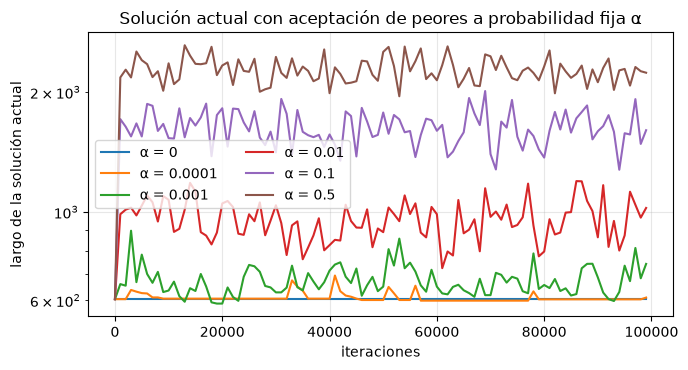

In [5]:
def busqueda_no_mejora(P, rnd, n_iter, alpha, t_ini):
    n = P.n; t = t_ini[:]; L = P.largo(t); mejor = L; tr_act = []
    for it in range(n_iter):
        i, j = sorted(rnd.sample(range(1, n), 2))
        dl = delta_2opt(P, t, i, j)
        if dl < 0 or rnd.random() < alpha:
            t = aplicar_2opt(t, i, j); L += dl
            if L < mejor: mejor = L
        if it % 1000 == 0: tr_act.append(L)
    return mejor, L, tr_act

t_ini, _ = local_2opt(P0, vecino_mas_cercano(P0), [0])
alphas = [0, 1e-4, 1e-3, 1e-2, 1e-1, 0.5]
filas = []
trazas = {}
for a in alphas:
    out = [busqueda_no_mejora(P0, random.Random(s), 100_000, a, t_ini) for s in range(8)]
    filas.append((a, np.mean([o[0] for o in out]), np.std([o[0] for o in out], ddof=1), np.mean([o[1] for o in out])))
    trazas[a] = out[0][2]
df_a = pd.DataFrame(filas, columns=["alpha", "mejor largo (media)", "desv. est.", "largo actual final (media)"])
df_a["alpha"] = df_a["alpha"].map(lambda a: f"{a:g}")
print(df_a.round(2).to_string(index=False))
print(f"(largo del punto de partida, 2-opt desde vecino más cercano: {P0.largo(t_ini):.1f})")

fig, ax = plt.subplots(figsize=(7, 3.8))
for a in alphas:
    ax.plot(np.arange(len(trazas[a])) * 1000, trazas[a], label=f"α = {a}")
ax.set_xlabel("iteraciones"); ax.set_ylabel("largo de la solución actual"); ax.set_yscale("log"); ax.legend(ncol=2)
ax.set_title("Solución actual con aceptación de peores a probabilidad fija α"); plt.tight_layout(); plt.show()

Observa dos regímenes: para $\alpha$ muy pequeño el comportamiento es el de un descenso con un poco de ruido; a partir de cierto valor la solución actual **se degrada** y se queda
deambulando muy por encima de la mejor encontrada. No hay ningún $\alpha$ constante que sirva a la vez para explorar al principio y refinar al final:
necesitamos una probabilidad que dependa de **cuánto** empeora el movimiento y que **disminuya con el tiempo**. Eso es exactamente el recocido simulado.

## 6. Recocido simulado: de dónde sale la probabilidad de Metropolis

### Analogía
Al recocer un metal se calienta y se enfría *lentamente*: a alta temperatura los átomos se mueven libremente; al bajar la temperatura se acomodan en estados de baja energía (un cristal).
Un enfriamiento brusco (temple) los deja atrapados en configuraciones de energía alta (mínimos locales). En optimización, la energía es $f(x)$ y la temperatura $T$ controla cuánta energía "prestada" se tolera.

### Distribución de Boltzmann
A temperatura $T$ constante, un sistema en equilibrio ocupa el estado $x$ con probabilidad
$$\pi_T(x)=\frac{e^{-f(x)/T}}{Z_T},\qquad Z_T=\sum_{y\in\mathcal{X}}e^{-f(y)/T}.$$
Dos propiedades importantes, con $f^\ast=\min f$ y $\mathcal{X}^\ast$ el conjunto de óptimos globales:
$$\pi_T(x)=\frac{e^{-(f(x)-f^\ast)/T}}{\sum_y e^{-(f(y)-f^\ast)/T}}\;\xrightarrow[T\to0]{}\;\begin{cases}1/|\mathcal{X}^\ast| & x\in\mathcal{X}^\ast\\ 0 & \text{si no}\end{cases}
\qquad\qquad \pi_T\xrightarrow[T\to\infty]{}\text{uniforme}.$$
Es decir: si pudiéramos muestrear de $\pi_T$ con $T$ pequeño, casi siempre caeríamos en un óptimo global. El obstáculo es muestrear, porque $Z_T$ no se puede calcular.

### Cadena de Markov de Metropolis
Construimos una cadena que **tiene a $\pi_T$ como distribución estacionaria** sin conocer $Z_T$. Sea $g(x\to y)$ la probabilidad de *proponer* $y$ desde $x$ (suponemos **simétrica**: $g(x\to y)=g(y\to x)$, como elegir un par $(i,j)$ uniforme para 2-opt)
y $a(x\to y)$ la probabilidad de *aceptar* la propuesta, de modo que $P(x\to y)=g(x\to y)\,a(x\to y)$ para $y\neq x$.

Una condición suficiente para que $\pi$ sea estacionaria es el **balance detallado**:
$$\pi(x)\,P(x\to y)=\pi(y)\,P(y\to x)\ \Longleftrightarrow\ \frac{a(x\to y)}{a(y\to x)}=\frac{\pi(y)}{\pi(x)}=e^{-(f(y)-f(x))/T}=e^{-\Delta/T},\quad \Delta=f(y)-f(x).$$
(El factor $Z_T$ se cancela, que es lo que hace útil el método.) Hay muchas elecciones de $a$ que cumplen esa razón; Metropolis toma la **mayor** posible, es decir, la que acepta con más frecuencia:

- Si $\Delta\le0$: $a(x\to y)=1$ (el movimiento inverso tiene $\Delta'=-\Delta\ge0$ y se acepta con $e^{\Delta/T}$, lo que cumple la razón exigida).
- Si $\Delta>0$: $a(x\to y)=e^{-\Delta/T}$ y $a(y\to x)=1$ (pues desde $y$ el movimiento a $x$ tiene $\Delta'=-\Delta<0$).

Comprobación: para $\Delta>0$, $\ \pi(x)\,g\,e^{-\Delta/T}=\dfrac{1}{Z}e^{-f(x)/T}e^{-(f(y)-f(x))/T}g=\dfrac1Z e^{-f(y)/T}g=\pi(y)\,g\cdot 1$. ✓.
Resumiendo en una sola fórmula:
$$\boxed{\,a(x\to y)=\min\!\left(1,\ e^{-\Delta/T}\right)\,}$$

Casos límite: $T\to\infty$: $a\to1$ (todo se acepta, paseo aleatorio); $T\to0^+$: $a\to \mathbb{1}[\Delta\le0]$ (descenso puro). Además, $a$ depende de $\Delta$ *relativo a $T$*: la misma $\Delta$ es "grande" a baja $T$ y "pequeña" a alta $T$.
(Existen otras reglas que satisfacen el balance detallado, como la de Barker $a=1/(1+e^{\Delta/T})$, pero acepta menos y el SA clásico usa Metropolis.)

**Qué cambia en SA respecto a Metropolis puro:** en SA la temperatura **decrece** con el tiempo; en cada nivel de temperatura se ejecuta una cadena de $L$ pasos de Metropolis ("longitud de cadena").

```
SA(x, T0, Tf, L, esquema):
    x* = x;  T = T0
    mientras T > Tf:
        repetir L veces:                       # cadena de Metropolis a T constante
            y = vecino aleatorio de x;  Δ = f(y) - f(x)
            si Δ <= 0  o  random() < exp(-Δ/T):  x = y
            si f(x) < f(x*): x* = x
        T = enfriar(T)
    devolver x*
```

### Verificación numérica de la derivación
Elegimos un TSP de $n=8$ ciudades: con la primera ciudad fija hay $7!=5040$ permutaciones, así que podemos **enumerar el espacio entero** y calcular la distribución de Boltzmann *exacta*.
Luego corremos una cadena de Metropolis a $T$ constante (propuesta: inversión 2-opt con $(i,j)$ uniforme, que es simétrica porque la misma inversión deshace el movimiento) y comparamos:
la energía media y la distribución del largo $f$ (por bins) de la cadena contra las de Boltzmann.

estados = 5040, f mínimo = 306.47, f medio uniforme = 514.73, f máximo = 688.74


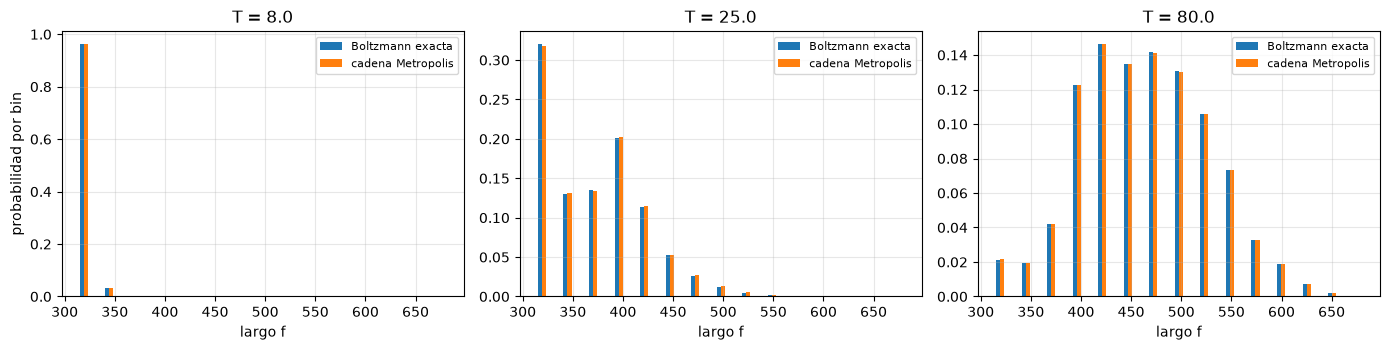

   T  E[f] Boltzmann  E[f] cadena  error rel. %  dist. variación total (bins)
 8.0        311.3364     311.2768        0.0191                        0.0018
25.0        367.2005     367.5725        0.1013                        0.0052
80.0        462.9846     462.9923        0.0017                        0.0012


In [6]:
P8 = TSP(8, seed=5)
estados = [[0] + list(p) for p in itertools.permutations(range(1, 8))]
fvals = np.array([P8.largo(s) for s in estados])
print(f"estados = {len(estados)}, f mínimo = {fvals.min():.2f}, f medio uniforme = {fvals.mean():.2f}, f máximo = {fvals.max():.2f}")

def boltzmann(T):
    w = np.exp(-(fvals - fvals.min()) / T)
    return w / w.sum()

def cadena_metropolis(P, rnd, T, n_iter, burn=20_000):
    n = P.n
    t = list(range(n)); rnd.shuffle(t); k0 = t.index(0); t = t[k0:] + t[:k0]
    L = P.largo(t); muestras = []
    for it in range(n_iter):
        i, j = sorted(rnd.sample(range(1, n), 2))
        dl = delta_2opt(P, t, i, j)
        if dl <= 0 or rnd.random() < math.exp(-dl / T):
            t = aplicar_2opt(t, i, j); L += dl
        if it >= burn: muestras.append(L)
    return np.array(muestras)

bins = np.linspace(fvals.min() - 1e-6, fvals.max() + 1e-6, 16)    # margen: el largo incremental acumula ruido de redondeo ~1e-13
filas = []
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, T in zip(axs, [8.0, 25.0, 80.0]):
    pi = boltzmann(T)
    E_exacto = float((pi * fvals).sum())
    m = cadena_metropolis(P8, random.Random(0), T, 1_000_000, burn=50_000)
    h_cad, _ = np.histogram(m, bins=bins); h_cad = h_cad / h_cad.sum()
    h_exa, _ = np.histogram(fvals, bins=bins, weights=pi)
    tv = 0.5 * np.abs(h_cad - h_exa).sum()
    filas.append((T, E_exacto, m.mean(), abs(m.mean() - E_exacto) / E_exacto * 100, tv))
    ctr = 0.5 * (bins[1:] + bins[:-1])
    ax.bar(ctr - 2, h_exa, width=4, label="Boltzmann exacta"); ax.bar(ctr + 2, h_cad, width=4, label="cadena Metropolis")
    ax.set_title(f"T = {T}"); ax.set_xlabel("largo f"); ax.legend(fontsize=8)
axs[0].set_ylabel("probabilidad por bin")
plt.tight_layout(); plt.show()
print(pd.DataFrame(filas, columns=["T", "E[f] Boltzmann", "E[f] cadena", "error rel. %", "dist. variación total (bins)"]).round(4).to_string(index=False))

La energía media de la cadena coincide con la exacta de Boltzmann (error relativo de a lo más unas décimas de punto porcentual, que es ruido de Monte Carlo: las muestras de una cadena están autocorrelacionadas, sobre todo a $T$ intermedia) y los histogramas se superponen:
la regla $\min(1,e^{-\Delta/T})$ **sí** produce la distribución de Boltzmann como estacionaria. Se ve también cómo, al bajar $T$, la masa se concentra en los $f$ bajos (a $T=8$ casi toda la probabilidad está en el óptimo).
Si alargas la cadena, la discrepancia residual se reduce.

### Probabilidad de aceptación en la práctica
Con $T$ en las mismas unidades que $f$, $a=e^{-\Delta/T}$ solo depende del cociente $\Delta/T$. Una regla útil: se acepta con probabilidad $1/2$ cuando $\Delta=T\ln2\approx0.69\,T$ y con probabilidad $\approx5\%$ cuando $\Delta=3T$.

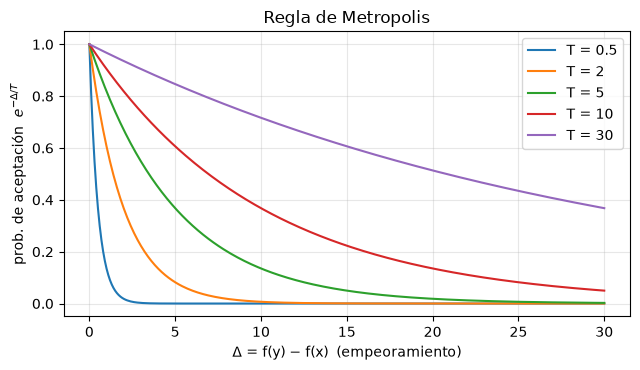

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
dd = np.linspace(0, 30, 300)
for T in [0.5, 2, 5, 10, 30]:
    ax.plot(dd, np.exp(-dd / T), label=f"T = {T}")
ax.set_xlabel("Δ = f(y) − f(x)  (empeoramiento)"); ax.set_ylabel("prob. de aceptación  $e^{-Δ/T}$")
ax.set_title("Regla de Metropolis"); ax.legend(); plt.tight_layout(); plt.show()

## 7. Implementación de SA para TSP

Escribimos un SA general con:
- **esquema de enfriamiento** (siguiente sección) dado como función del *nivel* de temperatura;
- **longitud de cadena** $L$ (iteraciones por nivel);
- **recalentamiento** opcional (`ciclos`): el calendario se repite varias veces, cada vez desde una temperatura inicial menor;
- registros: trayectoria de la solución actual y de la mejor, número de movimientos que empeoran propuestos/aceptados por nivel.

Cada iteración propone una inversión 2-opt aleatoria, calcula $\Delta$ en $O(1)$ y solo copia el tour si se acepta.
El largo se actualiza de forma incremental; al final lo comprobamos contra el recálculo completo.

In [8]:
def calendario(esquema, n_niveles, T0, Tf):
    '''Temperatura por nivel.'''
    k = np.arange(n_niveles)
    if esquema == "geométrico":
        alfa = (Tf / T0) ** (1.0 / max(1, n_niveles - 1))
        return T0 * alfa ** k
    if esquema == "lineal":
        return T0 + (Tf - T0) * k / max(1, n_niveles - 1)
    if esquema == "logarítmico":                    # T_k = c / ln(k + 2) con c tal que T_0 = T0
        return T0 * math.log(2) / np.log(k + 2)
    if esquema == "constante":
        return np.full(n_niveles, T0)
    raise ValueError(esquema)

def sa_tsp(P, rnd, n_iter, T0, Tf, esquema="geométrico", L=1, ciclos=1, factor_ciclo=0.5, t_ini=None, traza_cada=100):
    n = P.n
    t = t_ini[:] if t_ini is not None else rnd.sample(range(n), n)
    cur = P.largo(t); mejor_t, mejor = t, cur
    niv_total = max(1, n_iter // L)
    niv_ciclo = max(1, niv_total // ciclos)
    Ts = np.concatenate([calendario(esquema, niv_ciclo, T0 * factor_ciclo ** c, Tf) for c in range(ciclos)])
    Ts = np.concatenate([Ts, np.full(max(0, niv_total - len(Ts)), Ts[-1])])
    prop_peor = np.zeros(niv_total); acep_peor = np.zeros(niv_total)
    tr_cur, tr_best, tr_it = [], [], []; dl_acep = []; it = 0
    for lv in range(niv_total):
        T = float(Ts[lv])
        for _ in range(L):
            i, j = sorted(rnd.sample(range(1, n), 2))
            dl = delta_2opt(P, t, i, j)
            if dl <= 1e-9:
                t = aplicar_2opt(t, i, j); cur += dl
                if cur < mejor - 1e-12: mejor, mejor_t = cur, t
            else:
                prop_peor[lv] += 1
                if rnd.random() < math.exp(-dl / T):
                    t = aplicar_2opt(t, i, j); cur += dl; acep_peor[lv] += 1
                    dl_acep.append((it, dl))
            if traza_cada and it % traza_cada == 0:
                tr_it.append(it); tr_cur.append(cur); tr_best.append(mejor)
            it += 1
    return dict(t=mejor_t, L=mejor, Ts=Ts, prop=prop_peor, acep=acep_peor, it=np.array(tr_it),
                cur=np.array(tr_cur), best=np.array(tr_best), dl_acep=np.array(dl_acep), final_t=t, final_L=cur)

# Prueba de corrección
t_nn, _ = local_2opt(P0, vecino_mas_cercano(P0), [0])
out = sa_tsp(P0, random.Random(0), 60_000, T0=5.0, Tf=0.05, t_ini=t_nn)
assert es_tour(P0, out["t"]) and es_tour(P0, out["final_t"])
assert abs(P0.largo(out["t"]) - out["L"]) < 1e-6 and abs(P0.largo(out["final_t"]) - out["final_L"]) < 1e-6
print(f"punto de partida: {P0.largo(t_nn):.1f} | SA mejor: {out['L']:.1f} (largo incremental verificado == recalculado)")

punto de partida: 604.0 | SA mejor: 572.7 (largo incremental verificado == recalculado)


## 8. Esquemas de enfriamiento

Sea $T_k$ la temperatura del nivel $k$ ($k=0,\dots,K-1$).

| Esquema | Fórmula | Comentario |
|---|---|---|
| **Geométrico** | $T_k=T_0\,\alpha^k,\ \alpha=(T_f/T_0)^{1/(K-1)}$ | El más usado. Descenso rápido al inicio y lento en términos absolutos al final; razón de enfriamiento constante |
| **Lineal** | $T_k=T_0-k\,\dfrac{T_0-T_f}{K-1}$ | Pasa mucho tiempo a temperatura media; a baja $T$ cae abruptamente |
| **Logarítmico (Hajek)** | $T_k=\dfrac{c}{\ln(k+2)}$ | Único con garantía teórica de convergencia al óptimo global, pero impracticablemente lento |
| **Constante** | $T_k=T_0$ | Es Metropolis puro (sección 6); no converge a una solución, muestrea de Boltzmann |

### Resultado de Hajek (1988), en una frase
Sea $d^\ast$ la **profundidad máxima** de un mínimo local que no es global (la barrera más alta que hay que escalar para salir de él hacia algo mejor). Para $T_k=c/\ln(k+k_0)$, la cadena converge en probabilidad al conjunto de óptimos globales **si y solo si** $c\ge d^\ast$.
Idea de la prueba: la probabilidad de escapar de un mínimo local de profundidad $d$ en el paso $k$ es $\approx e^{-d/T_k}=(k+k_0)^{-d/c}$ y la serie $\sum_k (k+k_0)^{-d^\ast/c}$ diverge exactamente cuando $c\ge d^\ast$,
lo que garantiza infinitos intentos de escape. Pero el número de pasos necesario para tener alta probabilidad de estar en un óptimo es astronómico, algo inviable en la práctica.
En la práctica usamos enfriamiento geométrico con presupuesto finito y **no** hay garantía de óptimo; SA funciona como heurística.

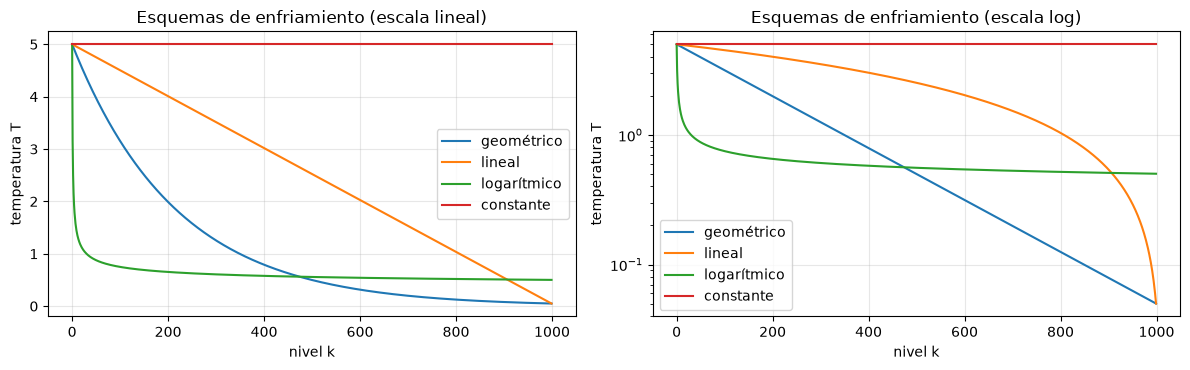

In [9]:
K = 1000
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for esq in ["geométrico", "lineal", "logarítmico", "constante"]:
    Ts = calendario(esq, K, 5.0, 0.05)
    axs[0].plot(Ts, label=esq); axs[1].plot(Ts, label=esq)
axs[0].set_title("Esquemas de enfriamiento (escala lineal)"); axs[1].set_title("Esquemas de enfriamiento (escala log)")
axs[1].set_yscale("log")
for ax in axs: ax.set_xlabel("nivel k"); ax.set_ylabel("temperatura T"); ax.legend()
plt.tight_layout(); plt.show()

### Comparación empírica de los esquemas (mismo número de iteraciones)
Todos arrancan desde el mismo tour (2-opt desde vecino más cercano), con $T_0=5$, $T_f=0.05$ (excepto el logarítmico, cuya $T_f$ queda determinada por $K$), 100 000 iteraciones,
$L=1$ (se enfría en cada iteración), 2 instancias $\times$ 8 semillas. Se reporta el mejor largo encontrado (media $\pm$ desv. est.).

In [10]:
instancias = [TSP(50, seed=10), TSP(50, seed=11)]
inicios = [local_2opt(P, vecino_mas_cercano(P), [0])[0] for P in instancias]
N_IT = 100_000

def correr_sa(esquema, T0=5.0, Tf=0.05, L=1, ciclos=1, n_sem=8, n_it=N_IT, factor_ciclo=0.5):
    res = []
    for ii, P in enumerate(instancias):
        for s in range(n_sem):
            o = sa_tsp(P, random.Random(100 * ii + s), n_it, T0, Tf, esquema, L=L, ciclos=ciclos, factor_ciclo=factor_ciclo, t_ini=inicios[ii], traza_cada=0)
            assert es_tour(P, o["t"])
            res.append((ii, s, o["L"]))
    return pd.DataFrame(res, columns=["inst", "sem", "L"])

t0 = time.perf_counter()
res_esq = {e: correr_sa(e) for e in ["geométrico", "lineal", "logarítmico", "constante"]}
print(f"({time.perf_counter() - t0:.0f} s)")
ref_inst = {ii: min(df[df.inst == ii]["L"].min() for df in res_esq.values()) for ii in range(2)}
filas = []
for e, df in res_esq.items():
    br = 100 * (df["L"] / df["inst"].map(ref_inst) - 1)
    filas.append((e, df["L"].mean(), df["L"].std(ddof=1), br.mean(), br.std(ddof=1)))
print(pd.DataFrame(filas, columns=["esquema", "largo medio", "desv. est.", "brecha media %", "desv. est. brecha %"]).round(2).to_string(index=False))

(8 s)
    esquema  largo medio  desv. est.  brecha media %  desv. est. brecha %
 geométrico       602.03       19.93            1.90                 1.82
     lineal       604.89       20.29            2.38                 1.80
logarítmico       640.09       25.45            8.33                 2.61
  constante       623.03       16.22            5.47                 1.77


Lectura (verifica contra la tabla): con un presupuesto finito, geométrico y lineal son competitivos; el **logarítmico** con $c=T_0\ln 2$ enfría demasiado poco: su temperatura final sigue siendo alta respecto a $\Delta$ típicos, y el resultado reportado es el *mejor visitado*, no el estado final;
la temperatura **constante** a $T_0$ solo muestrea de Boltzmann a esa temperatura y no refina. La lección práctica del teorema de Hajek es que "garantía asintótica" y "buen desempeño con presupuesto finito" son cosas distintas.

## 9. Temperatura inicial por tasa de aceptación objetivo

Elegir $T_0$ "a ojo" depende de las unidades de $f$. Un criterio independiente de la escala: fijar la **tasa de aceptación inicial** $\chi_0$ de los movimientos que empeoran, por ejemplo $\chi_0=0.8$ si se quiere exploración casi libre al comienzo.

**Procedimiento.** Muestrear $m$ movimientos aleatorios desde la solución inicial, quedarse con los que empeoran ($\Delta_i>0$) y resolver
$$\frac{1}{|\{\Delta_i>0\}|}\sum_{\Delta_i>0}e^{-\Delta_i/T_0}=\chi_0 .$$
Una aproximación en forma cerrada reemplaza los $\Delta_i$ por su media $\bar\Delta^+$: $T_0\approx -\bar\Delta^{+}/\ln\chi_0$. Esto **subestima** la tasa real por la desigualdad de Jensen ($e^{-x}$ es convexa, luego $\overline{e^{-\Delta/T}}\ge e^{-\bar\Delta/T}$),
así que resolver la ecuación por bisección es más preciso. Lo comprobamos.

In [11]:
def muestrear_deltas(P, t, rnd, m=3000):
    ds = []
    for _ in range(m):
        i, j = sorted(rnd.sample(range(1, P.n), 2))
        ds.append(delta_2opt(P, t, i, j))
    ds = np.array(ds)
    return ds[ds > 0]

def T0_por_tasa(dpos, chi0, exacto=True):
    if not exacto:
        return -dpos.mean() / math.log(chi0)
    f = lambda T: np.exp(-dpos / T).mean() - chi0
    return brentq(f, 1e-6, 1e6)

P = instancias[0]; t_base = inicios[0]
dpos = muestrear_deltas(P, t_base, random.Random(0))
print(f"Δ de movimientos que empeoran, desde el tour inicial: n={len(dpos)}, media={dpos.mean():.2f}, mediana={np.median(dpos):.2f}")
filas = []
for chi in [0.05, 0.2, 0.5, 0.8, 0.95]:
    T_apx, T_ex = T0_por_tasa(dpos, chi, False), T0_por_tasa(dpos, chi, True)
    tasa_apx = np.exp(-dpos / T_apx).mean()
    # tasa realizada en una cadena corta a T constante = T_ex, desde la misma solución
    o = sa_tsp(P, random.Random(1), 3000, T_ex, T_ex, "constante", t_ini=t_base, traza_cada=0)
    real = o["acep"].sum() / o["prop"].sum()
    filas.append((chi, T_apx, tasa_apx, T_ex, real))
print(pd.DataFrame(filas, columns=["χ0 objetivo", "T0 aprox. (media)", "tasa con T0 aprox.", "T0 exacto (bisección)", "tasa realizada (3000 it. a T0 exacto)"]).round(3).to_string(index=False))

Δ de movimientos que empeoran, desde el tour inicial: n=2995, media=75.72, mediana=72.97
 χ0 objetivo  T0 aprox. (media)  tasa con T0 aprox.  T0 exacto (bisección)  tasa realizada (3000 it. a T0 exacto)
        0.05             25.275               0.139                 11.509                                  0.087
        0.20             47.045               0.279                 34.365                                  0.378
        0.50            109.235               0.534                 97.573                                  0.722
        0.80            339.316               0.806                328.192                                  0.915
        0.95           1476.142               0.950               1465.211                                  0.977


La aproximación por la media da tasas **más bajas** que el objetivo (Jensen); la bisección da la tasa objetivo sobre la muestra de $\Delta$ iniciales.
La tasa realmente observada durante la cadena difiere algo del objetivo porque, a $T$ alta, la solución actual se degrada y la distribución de $\Delta$ cambia (por eso $\chi_0$ es un criterio *de arranque*).
Ahora medimos el efecto de $\chi_0$ sobre la calidad final, con $T_f$ fijo y mismo presupuesto.

In [12]:
Tf_fijo = 0.05
filas = []; Tinis = {}
for chi in [0.0005, 0.005, 0.05, 0.3, 0.6, 0.9]:
    T0c = float(np.mean([T0_por_tasa(muestrear_deltas(P, ini, random.Random(0)), chi) for P, ini in zip(instancias, inicios)]))
    Tinis[chi] = T0c
    df = correr_sa("geométrico", T0=T0c, Tf=Tf_fijo, n_sem=8)
    br = 100 * (df["L"] / df["inst"].map(ref_inst) - 1)
    filas.append((chi, T0c, df["L"].mean(), df["L"].std(ddof=1), br.mean()))
df_chi = pd.DataFrame(filas, columns=["χ0", "T0", "largo medio", "desv. est.", "brecha media %"])
df_chi["χ0"] = df_chi["χ0"].map(lambda c: f"{c:g}")
print(df_chi.round(2).to_string(index=False))

    χ0     T0  largo medio  desv. est.  brecha media %
0.0005   0.45       638.59       27.00            8.07
 0.005   2.44       624.67       31.00            5.69
  0.05  12.20       605.59       20.98            2.49
   0.3  53.43       607.86       19.78            2.88
   0.6 145.73       607.34       17.79            2.80
   0.9 757.33       614.59       25.32            4.01


Con $\chi_0$ muy bajo (tabla, primeras filas) el SA arranca demasiado frío y se comporta casi como un descenso: se atasca y el resultado es claramente peor.
Para $\chi_0$ moderado y alto el resultado se aplana (diferencias del orden de la desviación estándar), con un deterioro suave al subir $\chi_0$ porque se desperdicia parte del presupuesto enfriando desde un régimen casi aleatorio.
Un detalle específico de este problema: las inversiones 2-opt aleatorias de tramos largos tienen $\Delta$ enormes (la media de los $\Delta>0$ es del orden de decenas de unidades), por lo que un $\chi_0$ tan bajo como $0.05$ ya corresponde a un $T_0$ de decenas, y el rango "útil" de $\chi_0$ es más bajo que el $0.8$ que suele recomendarse en otros problemas. El valor adecuado depende del vecindario y del presupuesto: ajústalo, no lo copies.

## 10. Longitud de cadena y recalentamiento

### Longitud de cadena $L$
A presupuesto total $N$ fijo, hay una compensación: con $L$ pequeño se enfría en muchos niveles pero la cadena **no alcanza el equilibrio** en cada nivel;
con $L$ grande el equilibrio es mejor pero hay pocos niveles de temperatura (enfriamiento más brusco entre niveles). Con $N=100\,000$ comparamos $L\in\{1,10,100,1000,10000\}$ (geométrico).

In [13]:
T0_c = Tinis[0.05]
filas = []
for L in [1, 10, 100, 1000, 10000]:
    df = correr_sa("geométrico", T0=T0_c, Tf=Tf_fijo, L=L, n_sem=8)
    br = 100 * (df["L"] / df["inst"].map(ref_inst) - 1)
    filas.append((L, N_IT // L, df["L"].mean(), df["L"].std(ddof=1), br.mean()))
print(f"T0 = {T0_c:.2f} (χ0 = 0.05), Tf = {Tf_fijo}")
print(pd.DataFrame(filas, columns=["L (it./nivel)", "niveles", "largo medio", "desv. est.", "brecha media %"]).round(2).to_string(index=False))

T0 = 12.20 (χ0 = 0.05), Tf = 0.05
 L (it./nivel)  niveles  largo medio  desv. est.  brecha media %
             1   100000       605.59       20.98            2.49
            10    10000       606.34       20.27            2.62
           100     1000       603.43       19.86            2.14
          1000      100       605.83       19.62            2.54
         10000       10       610.21       22.81            3.28


Con este presupuesto las diferencias entre longitudes de cadena son pequeñas frente a la desviación estándar entre semillas (compara las columnas "largo medio" y "desv. est."); no hay una conclusión fuerte salvo que la compensación no es crítica en este rango.
Ese es un resultado honesto: no todos los parámetros importan igual, y reconocer cuáles no importan ahorra tiempo de ajuste.

### Recalentamiento
Si al enfriarse la búsqueda queda atrapada en un valle profundo, se puede **subir de nuevo la temperatura** (recalentar) y volver a enfriar. Implementamos `ciclos` = $R$ repeticiones del calendario de enfriamiento
(cada una con $N/R$ iteraciones), con temperatura inicial decreciente por ciclo ($T_0,\ T_0/2,\ T_0/4,\dots$) para que los ciclos tardíos refinen alrededor de lo ya encontrado. La búsqueda continúa desde la solución *actual* (no se reinicia).

In [14]:
filas = []
for R in [1, 2, 4, 8, 16]:
    df = correr_sa("geométrico", T0=T0_c, Tf=Tf_fijo, L=10, ciclos=R, n_sem=8)
    br = 100 * (df["L"] / df["inst"].map(ref_inst) - 1)
    filas.append((R, df["L"].mean(), df["L"].std(ddof=1), br.mean()))
print(pd.DataFrame(filas, columns=["ciclos R", "largo medio", "desv. est.", "brecha media %"]).round(2).to_string(index=False))

 ciclos R  largo medio  desv. est.  brecha media %
        1       606.34       20.27            2.62
        2       598.47       16.98            1.30
        4       603.99       20.01            2.23
        8       613.29       19.80            3.81
       16       616.72       20.69            4.39


Interpretación: el recalentamiento reparte el presupuesto entre varios enfriamientos *más cortos*. Con pocos ciclos el resultado se parece al de un solo enfriamiento, y con muchos ciclos (cada uno demasiado corto para enfriarse bien) el resultado empeora de forma visible en la tabla.
No se observa una ventaja clara del recalentamiento en esta instancia y presupuesto; podría ayudar con presupuestos mucho mayores, donde un solo enfriamiento ya satura. No hay un $R$ universal: es otro parámetro a ajustar
(véase [ajuste de parámetros](../05-evaluacion-y-ajuste/15-ajuste-de-parametros.ipynb)).

## 11. Visualización de la trayectoria de aceptación

Ejecutamos un SA largo (con $L=1$, $\chi_0=0.05$, geométrico) y graficamos cuatro cosas:
1. solución **actual** y **mejor** vs iteración (la actual sube y baja al inicio, y se estabiliza cuando $T$ baja);
2. el **calendario** de temperatura;
3. la **tasa de aceptación de los movimientos que empeoran** en ventanas de iteraciones frente a $T$ (cae hacia 0 al enfriarse: el sistema se "congela");
4. los $\Delta$ de los empeoramientos aceptados a lo largo del tiempo: al enfriarse solo pasan los pequeños.

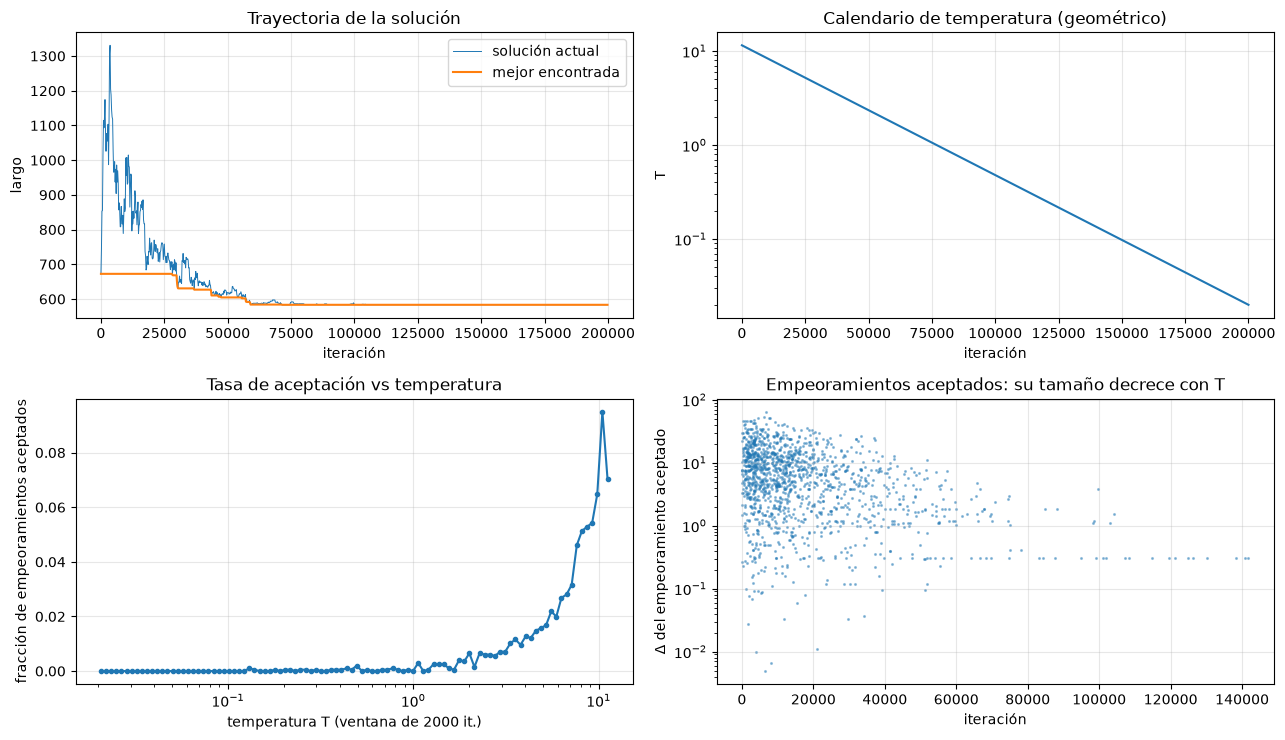

Empeoramientos aceptados: 1428 de 198379 propuestos (0.7%). Mejor largo: 583.4; largo del arranque: 672.5


In [15]:
P = instancias[0]
T0_05 = T0_por_tasa(muestrear_deltas(P, inicios[0], random.Random(0)), 0.05)
o = sa_tsp(P, random.Random(7), 200_000, T0_05, 0.02, "geométrico", L=1, t_ini=inicios[0], traza_cada=200)
assert es_tour(P, o["t"]) and abs(P.largo(o["t"]) - o["L"]) < 1e-6

fig, axs = plt.subplots(2, 2, figsize=(13, 7.5))
axs[0, 0].plot(o["it"], o["cur"], lw=0.7, label="solución actual"); axs[0, 0].plot(o["it"], o["best"], lw=1.5, label="mejor encontrada")
axs[0, 0].set_title("Trayectoria de la solución"); axs[0, 0].set_xlabel("iteración"); axs[0, 0].set_ylabel("largo"); axs[0, 0].legend()
axs[0, 1].plot(o["Ts"]); axs[0, 1].set_yscale("log"); axs[0, 1].set_title("Calendario de temperatura (geométrico)")
axs[0, 1].set_xlabel("iteración"); axs[0, 1].set_ylabel("T")

ventana = 2000
prop = o["prop"][: len(o["prop"]) // ventana * ventana].reshape(-1, ventana).sum(1)
acep = o["acep"][: len(o["acep"]) // ventana * ventana].reshape(-1, ventana).sum(1)
Tv = o["Ts"][: len(o["Ts"]) // ventana * ventana].reshape(-1, ventana).mean(1)
axs[1, 0].plot(Tv, acep / np.maximum(prop, 1), "o-", ms=3)
axs[1, 0].set_xscale("log"); axs[1, 0].set_xlabel("temperatura T (ventana de 2000 it.)"); axs[1, 0].set_ylabel("fracción de empeoramientos aceptados")
axs[1, 0].set_title("Tasa de aceptación vs temperatura")

da = o["dl_acep"]
axs[1, 1].scatter(da[:, 0], da[:, 1], s=1.5, alpha=0.4)
axs[1, 1].set_yscale("log"); axs[1, 1].set_xlabel("iteración"); axs[1, 1].set_ylabel("Δ del empeoramiento aceptado")
axs[1, 1].set_title("Empeoramientos aceptados: su tamaño decrece con T")
plt.tight_layout(); plt.show()
print(f"Empeoramientos aceptados: {len(da)} de {int(o['prop'].sum())} propuestos "
      f"({len(da)/o['prop'].sum():.1%}). Mejor largo: {o['L']:.1f}; largo del arranque: {P.largo(inicios[0]):.1f}")

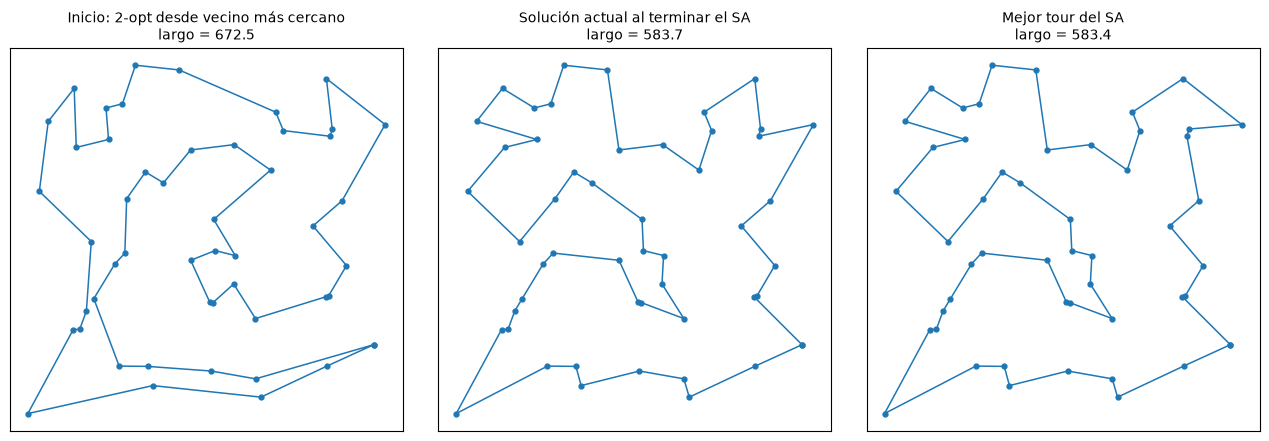

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4.3))
graficar_tour(P, inicios[0], axs[0], "Inicio: 2-opt desde vecino más cercano")
graficar_tour(P, o["final_t"], axs[1], "Solución actual al terminar el SA")
graficar_tour(P, o["t"], axs[2], "Mejor tour del SA")
plt.tight_layout(); plt.show()

## 12. SA en una función continua multimodal

SA no es exclusivo de problemas combinatorios. Para $f:\mathbb{R}^d\to\mathbb{R}$ la propuesta es $y=x+\sigma\,\mathcal{N}(0,I)$ (simétrica) y la aceptación es la misma $\min(1,e^{-\Delta/T})$.
Usamos la función de **Rastrigin**:
$$f(x)=10d+\sum_{i=1}^{d}\left(x_i^2-10\cos(2\pi x_i)\right),\qquad x_i\in[-5.12,5.12],\quad f^\ast=0\ \text{en}\ x=0,$$
con una red de mínimos locales en los enteros. Los mínimos locales no globales tienen $f\ge 1$ (aprox.), así que consideramos que la corrida **llegó a la cuenca global** si el mejor valor es $<0.5$.

La amplitud del paso se reduce con la temperatura, $\sigma_k=\sigma_0\sqrt{T_k/T_0}$, para refinar al final. Comparamos con un *descenso aleatorio* ($T=0$: solo se aceptan mejoras, mismo paso).

In [17]:
def rastrigin(x):
    x = np.asarray(x)
    return 10 * x.size + float(np.sum(x * x - 10 * np.cos(2 * np.pi * x)))

def sa_continuo(f, d, rng, n_iter, T0, Tf, sigma0=1.0, T_cero=False, lo=-5.12, hi=5.12, guardar=False):
    x = rng.uniform(lo, hi, d); fx = f(x); mejor_x, mejor = x.copy(), fx
    alfa = (Tf / T0) ** (1.0 / (n_iter - 1)); T = T0
    ruido = rng.standard_normal((n_iter, d)); u = rng.random(n_iter)
    tray = [x.copy()] if guardar else None; acept_peor = []
    for k in range(n_iter):
        sig = sigma0 * math.sqrt(T / T0)
        y = np.clip(x + sig * ruido[k], lo, hi); fy = f(y); dl = fy - fx
        if dl <= 0:
            x, fx = y, fy
        elif (not T_cero) and u[k] < math.exp(-dl / T):
            x, fx = y, fy
            if guardar: acept_peor.append(k)
        if fx < mejor: mejor, mejor_x = fx, x.copy()
        if guardar: tray.append(x.copy())
        T *= alfa
    return mejor, mejor_x, (np.array(tray) if guardar else None), acept_peor

def estudiar(d, n_iter, n_sem, T0, Tf, sigma0):
    res = {}
    for nombre, kw in [("SA (Metropolis)", dict(T_cero=False)), ("Descenso aleatorio (T=0)", dict(T_cero=True))]:
        res[nombre] = [sa_continuo(rastrigin, d, np.random.default_rng(s), n_iter, T0, Tf, sigma0, **kw)[0] for s in range(n_sem)]
    return res

t0 = time.perf_counter()
filas = []
for d, n_it, sem in [(2, 20_000, 30), (5, 40_000, 20)]:
    r = estudiar(d, n_it, sem, T0=10.0, Tf=0.01, sigma0=0.3)
    for nombre, v in r.items():
        v = np.array(v)
        filas.append((d, nombre, n_it, v.mean(), v.std(ddof=1), np.median(v), (v < 0.5).mean()))
print(f"({time.perf_counter() - t0:.0f} s)")
print(pd.DataFrame(filas, columns=["dim", "método", "iteraciones", "mejor f (media)", "desv. est.", "mediana", "frac. cuenca global"]).round(3).to_string(index=False))

(12 s)
 dim                   método  iteraciones  mejor f (media)  desv. est.  mediana  frac. cuenca global
   2          SA (Metropolis)        20000            0.417       0.455    0.213                0.667
   2 Descenso aleatorio (T=0)        20000           11.243       8.555    9.452                0.033
   5          SA (Metropolis)        40000            7.869       3.796    7.929                0.000
   5 Descenso aleatorio (T=0)        40000           37.164      11.962   36.816                0.000


Con **la misma** secuencia de pasos, el descenso aleatorio ($T=0$) queda atrapado en la cuenca del primer mínimo local; el SA, al aceptar empeoramientos mientras $T$ es alta,
puede cruzar las barreras entre mínimos y es más frecuente que termine en la cuenca global. Veamos una trayectoria en 2D: los puntos rojos son pasos aceptados que **empeoraron** $f$.

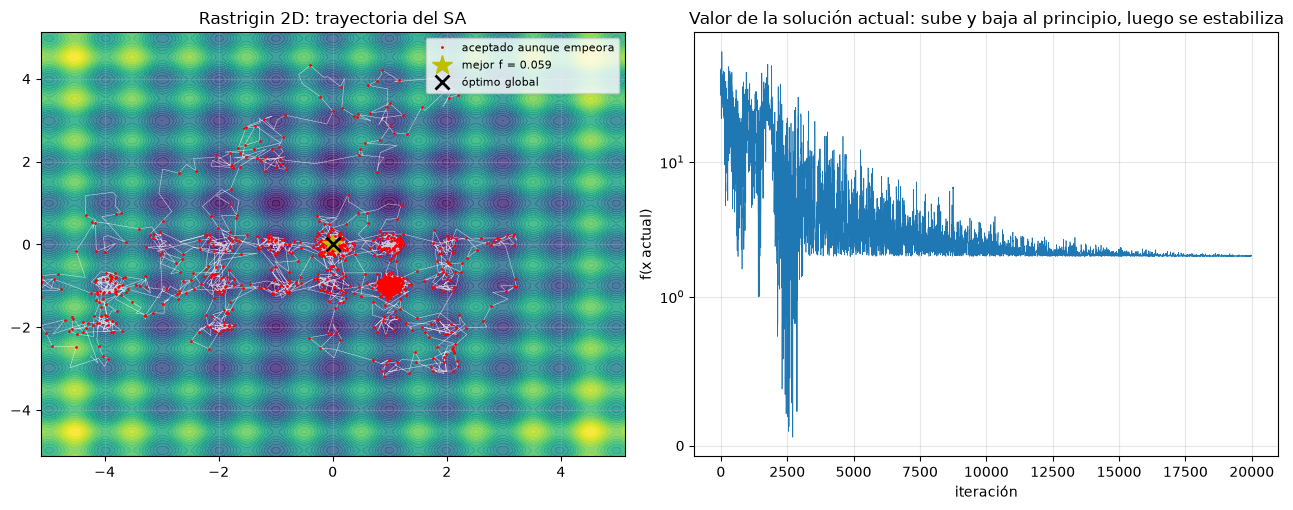

In [18]:
mejor, mx, tray, acp = sa_continuo(rastrigin, 2, np.random.default_rng(3), 20_000, 10.0, 0.01, 0.3, guardar=True)
g = np.linspace(-5.12, 5.12, 300); X, Y = np.meshgrid(g, g)
Z = 20 + X**2 + Y**2 - 10 * np.cos(2*np.pi*X) - 10 * np.cos(2*np.pi*Y)
fig, axs = plt.subplots(1, 2, figsize=(13, 5.2))
axs[0].contourf(X, Y, Z, 30, cmap="viridis", alpha=0.85)
axs[0].plot(tray[:, 0], tray[:, 1], "w-", lw=0.4, alpha=0.7)
acp = np.array(acp)
axs[0].plot(tray[acp + 1, 0], tray[acp + 1, 1], "r.", ms=2, label="aceptado aunque empeora")
axs[0].plot(*mx, "y*", ms=15, label=f"mejor f = {mejor:.3f}"); axs[0].plot(0, 0, "kx", ms=10, mew=2, label="óptimo global")
axs[0].set_title("Rastrigin 2D: trayectoria del SA"); axs[0].legend(loc="upper right", fontsize=8)
fs = np.array([rastrigin(p) for p in tray])
axs[1].plot(fs, lw=0.5); axs[1].set_yscale("symlog", linthresh=1); axs[1].set_xlabel("iteración"); axs[1].set_ylabel("f(x actual)")
axs[1].set_title("Valor de la solución actual: sube y baja al principio, luego se estabiliza")
plt.tight_layout(); plt.show()

Observa en el panel izquierdo que el SA visita varias cuencas antes de asentarse (los puntos rojos son aceptaciones de empeoramientos, más densas al principio) y en el derecho el valor actual de $f$ baja con la temperatura.
La estrella marca el mejor punto visitado, que no siempre coincide con donde termina la solución *actual*: por eso se guarda el mejor aparte. Si la temperatura baja demasiado rápido, la cadena puede congelarse en un mínimo local aunque antes haya pasado por la cuenca global.

## 13. Comparación final sobre TSP y cierre

Comparamos, con el **mismo número de evaluaciones de vecinos** ($N=100\,000$) y las mismas instancias y semillas:

| Método | Descripción |
|---|---|
| Reinicio + 2-opt | Reinicios aleatorios hasta agotar el presupuesto |
| (1+1)-ES ($\lambda=0.5$) | Sección 4 |
| Búsqueda con aceptación fija ($\alpha=10^{-3}$) | Sección 5 |
| ILS (doble puente) | Sección 3 |
| **SA** geométrico, $\chi_0=0.05$, $L=10$ | Secciones 7–10 |

Métrica: brecha respecto del mejor largo observado por instancia entre todos los métodos (no conocemos el óptimo). 3 instancias, 8 semillas; media $\pm$ desviación estándar y prueba de Wilcoxon pareada.

(11 s)
                          brecha media %  desv. est. %  mín %  máx %
metodo                                                              
Reinicio + 2-opt                    3.77          1.70   0.67   7.41
(1+1)-ES (λ=0.5)                    2.85          1.72   1.28   5.58
Aceptación fija (α=1e-3)            2.20          1.24   0.28   5.58
ILS (doble puente)                  1.74          1.38   0.00   4.86
SA geométrico                       1.52          1.49   0.00   5.11

Wilcoxon pareado (SA vs resto), 24 pares:
  SA vs Reinicio + 2-opt            dif. media = -2.24 pts %   p = 0.0000
  SA vs (1+1)-ES (λ=0.5)            dif. media = -1.32 pts %   p = 0.0002
  SA vs Aceptación fija (α=1e-3)    dif. media = -0.68 pts %   p = 0.0218
  SA vs ILS (doble puente)          dif. media = -0.21 pts %   p = 0.4223


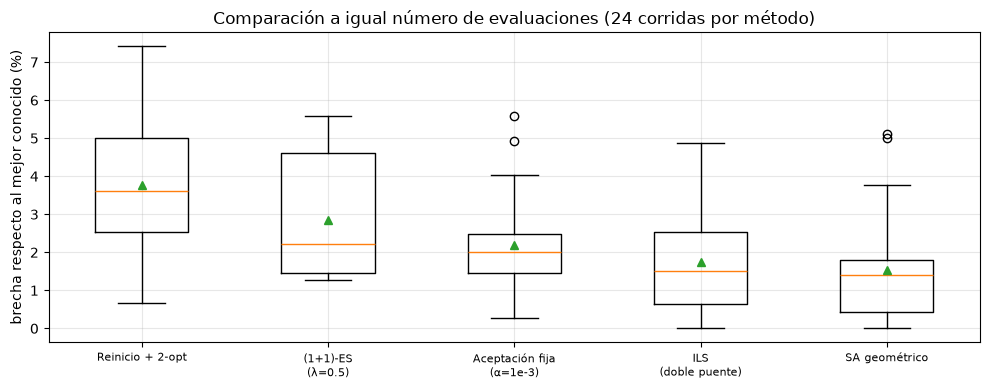

In [19]:
N_FIN = 100_000
inst_fin = [TSP(50, seed=20 + k) for k in range(3)]
ini_fin = [local_2opt(P, vecino_mas_cercano(P), [0])[0] for P in inst_fin]
T0_fin = [T0_por_tasa(muestrear_deltas(P, ini, random.Random(0)), 0.05) for P, ini in zip(inst_fin, ini_fin)]

def run_metodo(nombre, ii, s):
    P, ini, rnd = inst_fin[ii], ini_fin[ii], random.Random(1000 * ii + s)
    if nombre == "Reinicio + 2-opt":      return reinicio_aleatorio(P, rnd, N_FIN)
    if nombre == "(1+1)-ES (λ=0.5)":       return es_1mas1(P, rnd, N_FIN, 0.5, t_ini=ini)[1]
    if nombre == "Aceptación fija (α=1e-3)": return busqueda_no_mejora(P, rnd, N_FIN, 1e-3, ini)[0]
    if nombre == "ILS (doble puente)":    return ils_db(P, rnd, N_FIN)
    if nombre == "SA geométrico":
        return sa_tsp(P, rnd, N_FIN, T0_fin[ii], 0.05, "geométrico", L=10, t_ini=ini, traza_cada=0)["L"]

NOMBRES = ["Reinicio + 2-opt", "(1+1)-ES (λ=0.5)", "Aceptación fija (α=1e-3)", "ILS (doble puente)", "SA geométrico"]
t0 = time.perf_counter()
filas = [(m, ii, s, run_metodo(m, ii, s)) for m in NOMBRES for ii in range(3) for s in range(8)]
print(f"({time.perf_counter() - t0:.0f} s)")
dff = pd.DataFrame(filas, columns=["metodo", "inst", "sem", "L"])
ref = dff.groupby("inst")["L"].min()
dff["brecha"] = 100 * (dff["L"] / dff["inst"].map(ref) - 1)
res = dff.groupby("metodo")["brecha"].agg(["mean", "std", "min", "max"]).loc[NOMBRES]
res.columns = ["brecha media %", "desv. est. %", "mín %", "máx %"]
print(res.round(2).to_string())

piv = dff.pivot_table(index=["inst", "sem"], columns="metodo", values="brecha")[NOMBRES]
print("\nWilcoxon pareado (SA vs resto), 24 pares:")
for m in NOMBRES[:-1]:
    print(f"  SA vs {m:26s}  dif. media = {(piv['SA geométrico'] - piv[m]).mean():+.2f} pts %   p = {stats.wilcoxon(piv['SA geométrico'], piv[m]).pvalue:.4f}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([piv[m].values for m in NOMBRES], showmeans=True)
ax.set_xticklabels([m.replace(" (", "\n(") for m in NOMBRES], fontsize=8)
ax.set_ylabel("brecha respecto al mejor conocido (%)"); ax.set_title("Comparación a igual número de evaluaciones (24 corridas por método)")
plt.tight_layout(); plt.show()

### Lectura honesta
Con el mismo número de evaluaciones, 3 instancias y 8 semillas (las semillas son fijas, así que estos números son reproducibles):
- El reinicio aleatorio y la (1+1)-ES quedan claramente por detrás en la media (se quedan en óptimos locales), y el SA les gana con p de Wilcoxon muy pequeños.
- **SA e ILS** son los dos mejores y **no se distinguen** estadísticamente entre sí con 24 pares (p grande): afirmar que uno gana sería sobreinterpretar el ruido. SA sí supera de forma significativa a la aceptación a probabilidad fija, lo que ilustra el valor de hacer la aceptación dependiente de $\Delta$ y de $T$.
- El ILS con 2-opt es un competidor muy fuerte en TSP. La ventaja relativa del SA crece en espacios más rugosos o donde no hay una búsqueda local barata (por ejemplo la función continua de la sección 12).
- Los parámetros del SA ($T_0$, $T_f$, $L$, esquema) se fijaron tras la exploración de las secciones 8–10 con pocas semillas, no mediante un ajuste exhaustivo; una comparación con *cada método en su mejor configuración* podría cambiar el orden.

### Ventajas y limitaciones

| Aspecto | Ventajas | Limitaciones |
|---|---|---|
| **Reinicio / construcción aleatorizada** | Triviales; paralelizables; sin parámetros | No usan información de las búsquedas previas; rendimientos decrecientes |
| **(1+1)-ES** | Una línea de código; elitista; buena base de comparación | Se atasca en mesetas/óptimos locales si la mutación es pequeña |
| **Aceptación a probabilidad fija** | Escapa de óptimos locales | No distingue empeoramientos grandes de pequeños; no se "congela" |
| **Recocido simulado** | Base probabilística clara (Boltzmann); un solo parámetro principal por el que mover la exploración ($T$); sirve en discretos y continuos; implementación mínima | Muy sensible a $T_0$, calendario y $L$; convergencia garantizada solo con enfriamiento logarítmico (inviable); sin memoria; la temperatura depende de la escala de $f$ |

### Resumen
- El azar entra por reinicio, construcción aleatorizada y perturbación; la perturbación guiada por el óptimo actual (ILS) suele ser la más eficiente.
- La regla de Metropolis $\min(1,e^{-\Delta/T})$ es la **elección máxima** que cumple balance detallado con Boltzmann como distribución estacionaria. Lo comprobamos enumerando un TSP de $n=8$.
- El enfriamiento convierte la cadena de Metropolis en optimizador: $T$ alta explora, $T$ baja intensifica. Hajek da la garantía asintótica logarítmica; en la práctica se usa el geométrico.
- $T_0$ se fija por tasa de aceptación objetivo (mejor resolviendo la ecuación que con la media de $\Delta$); $L$ y el recalentamiento reparten un presupuesto finito entre equilibrio y niveles.
- Compara con presupuesto igual de **evaluaciones**, varias instancias y semillas, y reporta media $\pm$ desviación.

Siguiente: [06 Búsqueda tabú](../02-metodos-con-memoria/06-busqueda-tabu.ipynb), que añade **memoria** en lugar de aleatoriedad para escapar de óptimos locales.
Para el uso de SA como criterio de aceptación dentro de LNS, ver [04](04-vns-lns.ipynb).

## Ejercicios propuestos

1. **Balance detallado con otra regla**: repite la verificación numérica de la sección 6 con la regla de Barker $a=1/(1+e^{\Delta/T})$. ¿La distribución estacionaria sigue siendo Boltzmann? ¿Cómo cambia la tasa de aceptación?
2. **Propuesta asimétrica**: modifica el generador de vecinos para que no sea simétrico (p. ej. elegir $i$ con probabilidad no uniforme). Muestra numéricamente que Metropolis deja de muestrear Boltzmann y deriva la corrección de Metropolis-Hastings.
3. **Hajek**: estima la profundidad $d^\ast$ del TSP de $n=8$ por enumeración y corre SA con $T_k=c/\ln(k+2)$ para $c<d^\ast$ y $c>d^\ast$; compara la probabilidad de terminar en el óptimo global.
4. **Enfriamiento adaptativo**: ajusta $T$ para que la tasa de aceptación siga un objetivo decreciente (en lugar de un calendario fijo). Compara con el geométrico.
5. **SA con búsqueda local**: tras cada aceptación aplica una pasada de or-opt. ¿Cuánto cambia la calidad por evaluación?
6. **(1+1)-ES con regla del 1/5**: para Rastrigin en $\mathbb{R}^d$, adapta $\sigma$ de modo que la tasa de éxito sea $\approx 1/5$ y compara con el SA de la sección 12.
7. **Escalado**: estudia cómo cambia el $L$ óptimo al aumentar $n$ (30, 50, 80). ¿Crece como $n$?

## Referencias

- Metropolis, N., Rosenbluth, A. W., Rosenbluth, M. N., Teller, A. H. y Teller, E. (1953). *Equation of state calculations by fast computing machines*. Journal of Chemical Physics, 21(6).
- Kirkpatrick, S., Gelatt, C. D. y Vecchi, M. P. (1983). *Optimization by simulated annealing*. Science, 220(4598).
- Černý, V. (1985). *Thermodynamical approach to the traveling salesman problem: an efficient simulation algorithm*. Journal of Optimization Theory and Applications, 45.
- Hajek, B. (1988). *Cooling schedules for optimal annealing*. Mathematics of Operations Research, 13(2).
- van Laarhoven, P. J. M. y Aarts, E. H. L. (1987). *Simulated Annealing: Theory and Applications*. Reidel.
- Johnson, D. S., Aragon, C. R., McGeoch, L. A. y Schevon, C. (1989). *Optimization by simulated annealing: an experimental evaluation; part I, graph partitioning*. Operations Research, 37(6).
- Rechenberg, I. (1973). *Evolutionsstrategie: Optimierung technischer Systeme nach Prinzipien der biologischen Evolution*. Frommann-Holzboog.
- Martin, O., Otto, S. W. y Felten, E. W. (1991). *Large-step Markov chains for the traveling salesman problem*. Complex Systems, 5(3).
- Lourenço, H. R., Martin, O. C. y Stützle, T. (2003). *Iterated local search*. En Handbook of Metaheuristics (Glover y Kochenberger, eds.), Springer.
- Feo, T. A. y Resende, M. G. C. (1995). *Greedy randomized adaptive search procedures*. Journal of Global Optimization, 6.